# 08 · Source outcome and feature sensitivity

## Summary

Our source audit supports changing 39 outcomes from Pending to Passed for this comparison. On the same 894 bills from 2025, corrected training labels raise macro F1 from 0.518 to 0.531, but the state-bootstrap interval includes zero. On a text-screened cohort, adding bill text raises macro F1 from 0.538 to 0.588. Removing sponsor features slightly improves F1 but lowers accuracy; stronger regularization and NCSL descriptions do not improve that comparison.

These are exploratory development comparisons performed after model selection. They do not replace the 2026 final evaluation in notebook 07 or change the selected model.

## Methods and limits

We use the existing balanced linear SVM with C=10. Imputation, scaling, categorical encoding and TF-IDF are fitted on training data only. The code below records the text-vectorization settings; the C=0.1 comparison changes regularization.

Training bills were introduced in 2019–2024, and evaluation bills in 2025. We accept dated outcome corrections through **December 31, 2024** for training and **December 31, 2025** for evaluation. Unresolved labels remain as recorded. Both label comparisons use the same corrected evaluation labels.

Source-version dates screen text against those cutoffs, but do not reconstruct historical versions. Sponsor metadata, political control and NCSL description dates are not reconstructed at introduction. Earlier-year folds reuse the corrected snapshot and the 2024/2025 text screen, so they are not point-in-time backtests. Selective outcome checks and examining the final model before these comparisons also limit the conclusions.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = Path.cwd()
if not (REPO / "src" / "source_sensitivity.py").exists():
    REPO = REPO.parent
if not (REPO / "src" / "source_sensitivity.py").exists():
    raise FileNotFoundError("Run from the repository root or notebooks directory.")
sys.path.insert(0, str(REPO))

from src.source_sensitivity import (
    FEATURE_GROUPS, MODEL_PARAMS, TFIDF_PARAMS, NO_SPONSORS, NO_STATE,
    load_cohort, screen_text_versions, compare_models, paired_state_bootstrap,
)

OUTPUT = REPO / "outputs" / "source_sensitivity"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})
pd.set_option("display.max_columns", 12)


## Source coverage

The [saved audit](../data/validation/source_outcome_audit.csv) links matched bills to public LegiScan pages and records the dated evidence. It matches 1,523 of 1,636 candidates after excluding one source-dated 2025 record belonging to a 2026 session. We independently resolved outcomes for 311 matches; the rest retain source labels we could not independently verify. For this comparison, the audit supports changing 39 labels from Pending to Passed.

We do not apply five proposed veto-based Failed corrections because the saved evidence does not establish that veto consideration ended by the cutoff. The bills remain in the data with their source labels. The source table and its original 2026 rows are unchanged.

In [2]:
data = load_cohort(REPO)
coverage = data.groupby("split").agg(
    Rows=("source_row", "size"), Label_changes=("label_changed", "sum"),
    Independently_resolved=("independently_resolved", "sum"),
    Date_changes=("date_changed", "sum"), Year_changes=("cohort_changed", "sum"),
)
assert coverage.loc["training", "Rows"] == 629
assert coverage.loc["evaluation", "Rows"] == 894
assert data.label_changed.sum() == 39
assert data.independently_resolved.sum() == 311
assert data.loc[data.label_changed, "original_label"].eq("Pending").all()
assert data.loc[data.label_changed, "repaired_label"].eq("Passed").all()
withheld = data.loc[data.source_row.isin([38, 44, 68, 895, 901])]
assert len(withheld) == 5 and not withheld.label_changed.any()
assert not withheld.independently_resolved.any()
display(coverage)


,Rows,Label_changes,Independently_resolved,Date_changes,Year_changes
split,,,,,
evaluation,894,21,182,0,0
training,629,18,129,0,0


## Training-label repair

Only the training labels differ between the two fits. Both use the same 894 evaluation bills and corrected evaluation labels. The independently resolved subset is a diagnostic, not a representative test set. Macro F1 and balanced accuracy average the classes present in each subset's true labels.

In [3]:
training = data.loc[data.split.eq("training")]
evaluation = data.loc[data.split.eq("evaluation")]
label_scores, label_classes, label_predictions = compare_models(
    training, evaluation,
    [{"name": "Original labels", "target": "original_label"},
     {"name": "Repaired labels", "target": "repaired_label"}],
    comparison="Label repair", include_resolved=True,
)
display(label_scores[["Model", "Subset", "Rows", "Accuracy", "Balanced_accuracy", "Macro_F1"]].round(4))


,Model,Subset,Rows,Accuracy,Balanced_accuracy,Macro_F1
0,Original labels,All matched bills,894,0.6230,0.5403,0.5180
1,Original labels,Independently resolved,182,0.3077,0.5051,0.3460
2,Repaired labels,All matched bills,894,0.6197,0.5545,0.5308
3,Repaired labels,Independently resolved,182,0.3462,0.5293,0.3788


,Resamples,Seed,State_clusters,Macro_F1_difference,Lower_95,Upper_95,Predictions_changed
0,2000,42,49,0.0127,-0.0028,0.03,32


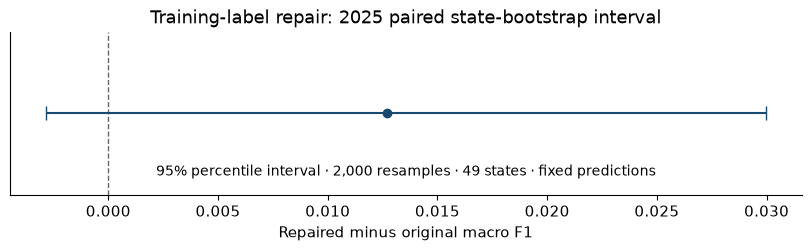

In [4]:
uncertainty = paired_state_bootstrap(label_predictions, resamples=2000, seed=42)
display(uncertainty.drop(columns=["Comparison", "Method"]).round(4))

interval = uncertainty.iloc[0]
fig, ax = plt.subplots(figsize=(8, 2.4), layout="constrained")
ax.axvline(0, color="#666666", linewidth=1, linestyle="--")
ax.errorbar(interval.Macro_F1_difference, 0,
            xerr=[[interval.Macro_F1_difference - interval.Lower_95],
                  [interval.Upper_95 - interval.Macro_F1_difference]],
            fmt="o", color="#174A6E", capsize=5)
ax.set(yticks=[], xlabel="Repaired minus original macro F1",
       title="Training-label repair: 2025 paired state-bootstrap interval")
ax.text(0.5, 0.12, "95% percentile interval · 2,000 resamples · 49 states · fixed predictions",
        transform=ax.transAxes, ha="center", fontsize=10)
plt.show()


The F1 gain is small and uncertain: the 95% interval includes zero, and accuracy falls slightly. We resample states while keeping each pair of predictions together. The interval reflects these fitted models and excludes training, audit and model-selection uncertainty.

## Matched metadata and text comparisons

We exclude eight training and 20 evaluation records whose source text version is missing or later than the split cutoff. Each comparison uses the remaining **621 training and 874 evaluation bills**, corrected labels and balanced class weights.

We compare adding bill text, removing sponsor features or jurisdiction, using stronger regularization after sponsor removal, and using NCSL descriptions instead of bill text. These checks use previously examined development results; they are not a new model-selection exercise.

In [5]:
text_data, excluded_text = screen_text_versions(data)
assert text_data.split.eq("training").sum() == 621
assert text_data.split.eq("evaluation").sum() == 874
assert len(excluded_text) == 28
display(excluded_text.groupby("split").size().rename("Excluded text versions").to_frame())

feature_configurations = [
    {"name": "Metadata"},
    {"name": "Metadata + bill text", "text_column": "Bill_Text_clean"},
    {"name": "No sponsors + bill text", "text_column": "Bill_Text_clean", "feature_groups": NO_SPONSORS},
    {"name": "No state + bill text", "text_column": "Bill_Text_clean", "feature_groups": NO_STATE},
    {"name": "No sponsors + bill text, C=0.1", "text_column": "Bill_Text_clean", "feature_groups": NO_SPONSORS, "C": 0.1},
    {"name": "No sponsors + NCSL descriptions", "text_column": "NCSL_Summary_clean", "feature_groups": NO_SPONSORS},
]
feature_scores, feature_classes, feature_predictions = compare_models(
    text_data.loc[text_data.split.eq("training")],
    text_data.loc[text_data.split.eq("evaluation")],
    feature_configurations, comparison="Text and feature checks",
)
display(feature_scores[["Model", "Training_accuracy", "Accuracy", "Balanced_accuracy", "Macro_F1"]].round(4))


,Excluded text versions
split,
evaluation,20
training,8


,Model,Training_accuracy,Accuracy,Balanced_accuracy,Macro_F1
0,Metadata,0.7568,0.6247,0.5601,0.5381
1,Metadata + bill text,1.0000,0.6476,0.6070,0.5882
2,No sponsors + bill text,0.9984,0.6453,0.6101,0.5906
3,No state + bill text,1.0000,0.5950,0.5593,0.5350
4,"No sponsors + bill text, C=0.1",0.8438,0.6236,0.5715,0.5443
5,No sponsors + NCSL descriptions,0.9775,0.6224,0.5845,0.5631


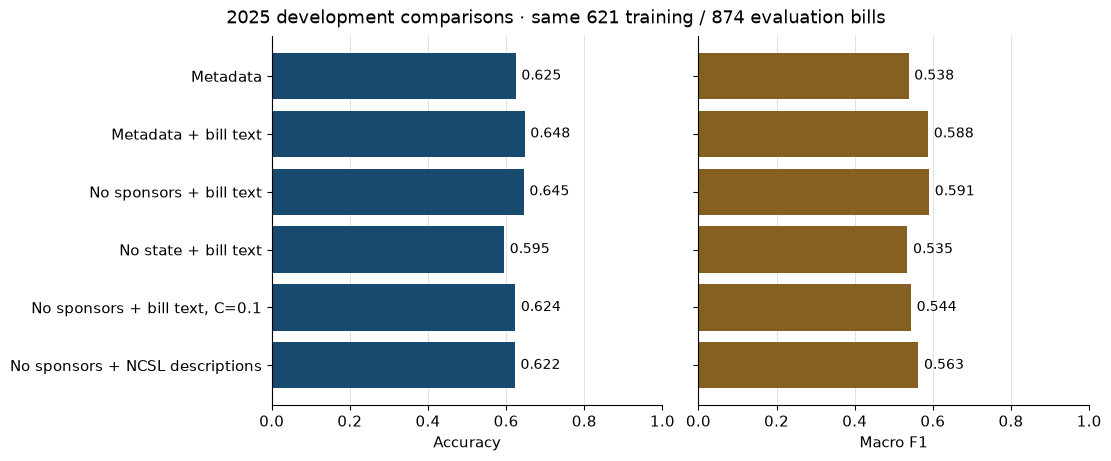

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained", sharey=True)
for ax, metric, color in zip(axes, ["Accuracy", "Macro_F1"], ["#174A6E", "#866021"]):
    bars = ax.barh(feature_scores.Model, feature_scores[metric], color=color)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)
    ax.set(xlim=(0, 1), xlabel=metric.replace("_", " "))
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()
fig.suptitle("2025 development comparisons · same 621 training / 874 evaluation bills")
plt.show()


Bill text improves the matched 2025 result. Removing sponsor features slightly increases F1 but lowers accuracy. Removing jurisdiction performs worse, and stronger regularization and NCSL descriptions do not improve the sponsor-free model. These checks do not establish a replacement model.

### Outcome-specific performance

Precision, recall and support by class show how each comparison performs on Passed bills. The complete table is saved below.

In [7]:
selected_models = ["Metadata", "Metadata + bill text", "No sponsors + bill text"]
display(feature_classes.loc[feature_classes.Model.isin(selected_models),
    ["Model", "Class", "Precision", "Recall", "F1", "Support"]].round(4))


,Model,Class,Precision,Recall,F1,Support
0,Metadata,Failed,0.4554,0.7951,0.5791,244
1,Metadata,Passed,0.3267,0.2276,0.2683,145
2,Metadata,Pending,0.9193,0.6577,0.7668,485
3,Metadata + bill text,Failed,0.4684,0.8197,0.5961,244
4,Metadata + bill text,Passed,0.4766,0.3517,0.4048,145
5,Metadata + bill text,Pending,0.9265,0.6495,0.7636,485
6,No sponsors + bill text,Failed,0.4762,0.7787,0.5910,244
7,No sponsors + bill text,Passed,0.4328,0.4000,0.4158,145
8,No sponsors + bill text,Pending,0.9267,0.6515,0.7651,485


## Earlier-year checks

We compare the same metadata and metadata-plus-text configurations on 2022, 2023 and 2024 separately. These checks use the retrospective snapshot; labels, metadata and text were not reconstructed as known at each historical cutoff.

In [8]:
earlier_runs = []
for year in [2022, 2023, 2024]:
    earlier_runs.append(compare_models(
        text_data.loc[text_data.year.lt(year)], text_data.loc[text_data.year.eq(year)],
        feature_configurations[:2], comparison="Earlier-year snapshot",
    ))
earlier_scores = pd.concat([run[0] for run in earlier_runs], ignore_index=True)
display(earlier_scores[["Year", "Model", "Training_rows", "Rows", "Accuracy", "Macro_F1"]].round(4))


,Year,Model,Training_rows,Rows,Accuracy,Macro_F1
0,2022,Metadata,116,23,0.6957,0.6053
1,2022,Metadata + bill text,116,23,0.5217,0.3889
2,2023,Metadata,139,85,0.2118,0.2492
3,2023,Metadata + bill text,139,85,0.2471,0.2916
4,2024,Metadata,224,397,0.6398,0.5981
5,2024,Metadata + bill text,224,397,0.6725,0.6421


Text improves accuracy and macro F1 in 2023 and 2024, but performs worse on the 23-bill 2022 cohort. The results vary by year.

## Save results

The saved files include the cohort, scores, predictions, uncertainty interval and run settings. They can be regenerated from the prepared data and saved audit without an API key or internet connection.

In [9]:
scores = pd.concat([label_scores, feature_scores, earlier_scores], ignore_index=True)
class_scores = pd.concat([label_classes, feature_classes] + [run[1] for run in earlier_runs], ignore_index=True)
predictions = pd.concat([label_predictions, feature_predictions] + [run[2] for run in earlier_runs], ignore_index=True)
cohort_columns = [
    "source_row", "Bill_Number", "Jurisdiction", "source_date", "analysis_date", "year", "split",
    "original_label", "repaired_label", "label_changed", "independently_resolved",
    "correction_evidence_date", "cutoff", "source_version_date", "source_url", "reason",
]
cohort = data[cohort_columns].assign(Text_eligible=data.source_row.isin(text_data.source_row))
for name, table in {"cohort": cohort, "scores": scores, "class_scores": class_scores,
                    "predictions": predictions, "uncertainty": uncertainty}.items():
    table.to_csv(OUTPUT / f"{name}.csv", index=False)

settings = {
    "training_years": [2019, 2024], "evaluation_year": 2025,
    "outcome_and_text_cutoffs": {"training": "2024-12-31", "evaluation": "2025-12-31"},
    "feature_groups": FEATURE_GROUPS, "model_params": MODEL_PARAMS, "tfidf_params": TFIDF_PARAMS,
    "feature_configurations": feature_configurations, "earlier_years": [2022, 2023, 2024],
    "bootstrap": {"resamples": 2000, "seed": 42, "clusters": "Jurisdiction"},
    "scope": "Post-selection exploratory development comparisons; original 2026 final evaluation unchanged.",
    "timing_limit": "Earlier folds reuse retrospective labels and the 2024/2025 text screen; metadata and NCSL dates are not reconstructed.",
    "metric_convention": "Macro F1 and balanced accuracy average observed true classes; bootstrap averages all three classes.",
}
(OUTPUT / "settings.json").write_text(json.dumps(settings, indent=2) + "\n", encoding="utf-8")
print(f"Saved {len(scores)} score rows and {len(predictions):,} predictions to outputs/source_sensitivity.")


Saved 16 score rows and 8,042 predictions to outputs/source_sensitivity.


## Conclusion and rerun

The label corrections make a modest difference, and adding text improves the matched 2025 comparison. Unverified labels, retrospective inputs, mixed earlier-year results and the post-selection design mean these findings do not replace the 2026 final test. The selected model is unchanged.

After setting up the project environment and running `python src/prepare.py`, run from the repository root:

```bash
python -m nbconvert --execute --to notebook --inplace --ExecutePreprocessor.kernel_name=state-ai-policy --ExecutePreprocessor.timeout=600 notebooks/08_source_sensitivity.ipynb
```

Sources: `data/processed/common_records.csv`; `data/validation/source_outcome_audit.csv` and its public source URLs; `src/classification_helpers.py`; `src/topic_analysis.py`.